# Is the ticket a useful feature?

A linear model of survival is fitted on the basic features, then again with ticket features added, and both are scored by cross-validation on the 891 train passengers.

**Basic features.** Class, sex, age, siblings and spouses aboard (SibSp), parents and children aboard (Parch), fare and port of embarkation. Age is missing for 20% of train: the gap is filled with the median age of the training folds, and a flag marks who was filled. Fare is log-transformed.

**Ticket features**, as defined in `tickets_v1.ipynb`:

- **Ticket type**: the prefix (`PC`, `C.A.`, ...) or Number only. Types with fewer than 8 passengers are grouped.
- **Ticket group size**: how many passengers, in train and test, hold the same ticket.
- **Number band**: length of the ticket number and its first digit (`3xxxxx`). Bands with fewer than 5 passengers are grouped.
- **Number window**: more leading digits (`347xxx`, `PC 175xx`). Windows with fewer than 5 passengers fall back to their band.

None of the ticket features uses survival, so building them on train and test together does not leak the answer.

**Models.** Logistic regression (the linear model for a yes/no outcome) with numeric inputs standardised, categories one-hot encoded as 0/1 columns, and default L2 regularisation (C = 1). Linear regression on the 0/1 outcome, predicting survival where the fitted value is 0.5 or more, is shown alongside as asked.

**Cross-validation.** 10 folds, repeated 10 times with different shuffles: 100 fits per model, each scored on the tenth of train it did not see. Every model sees the same 100 splits, so the difference to the basic model is measured split by split.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"], "font.size": 9.5,
    "text.color": INK, "axes.edgecolor": AXIS, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.facecolor": SURFACE, "figure.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110,
})

def find_data():
    from pathlib import Path
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data" / "complete_data.csv").exists():
            return p / "data" / "complete_data.csv"
c = pd.read_csv(find_data())

# Ticket features, built on train and test together (no survival used)
def raw_prefix(t):
    parts = t.split(" ")
    if t.replace(" ", "").isdigit():
        return ""
    return " ".join(parts[:-1]) if parts[-1].isdigit() else t
c["TicketType"] = c["Ticket"].map(lambda t: "Number only" if raw_prefix(t) == "" else re.sub(r"[./ ]", "", raw_prefix(t)).upper())
c["TicketNum"] = pd.to_numeric(c["Ticket"].str.extract(r"(\d+)$")[0])
def windows(row):
    t, n = row["TicketType"], row["TicketNum"]
    pre = "" if t == "Number only" else t + " "
    if pd.isna(n):
        return pd.Series([pre.strip(), pre.strip()])
    s = str(int(n)); d = len(s)
    k = min(d, 3 if (d >= 6 or t == "PC") else 2 if d >= 4 else 1)
    return pd.Series([pre + s[0] + "x" * (d - 1), pre + s[:k] + "x" * (d - k)])
c[["Band", "Window"]] = c.apply(windows, axis=1)
vc = c["TicketType"].value_counts(); c["TicketTypeG"] = c["TicketType"].where(c["TicketType"].map(vc) >= 8, "Other")
vb = c["Band"].value_counts();       c["BandG"] = c["Band"].where(c["Band"].map(vb) >= 5, "Rare band")
vw = c["Window"].value_counts();     c["WindowG"] = c["Window"].where(c["Window"].map(vw) >= 5, c["BandG"])
c["TicketCount"] = c.groupby("Ticket")["PassengerId"].transform("size")
c["LogFare"] = np.log1p(c["Fare"])
c["AgeMissing"] = c["Age"].isna().astype(int)
c["Pclass"] = c["Pclass"].astype(str)
c["Embarked"] = c["Embarked"].fillna("S")

tr = c[c["Dataset"] == "train"].reset_index(drop=True)
y = tr["Survived"].astype(int).values

BASIC_CAT = ["Pclass", "Sex", "Embarked"]
BASIC_NUM = ["Age", "AgeMissing", "SibSp", "Parch", "LogFare"]
SETS = {
    "Basic": ([], []),
    "+ ticket type": (["TicketTypeG"], []),
    "+ ticket group size": ([], ["TicketCount"]),
    "+ number band": (["BandG"], []),
    "+ number window": (["WindowG"], []),
    "+ all ticket features": (["TicketTypeG", "BandG", "WindowG"], ["TicketCount"]),
}

def pipe(cat, num, model):
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), BASIC_CAT + cat),
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), BASIC_NUM + num),
    ])
    return make_pipeline(pre, model)

display(Markdown(
    f"{len(tr)} train passengers, {y.mean():.0%} survived. Always predicting death would score {1 - y.mean():.1%} accuracy. "
    f"Extra columns each ticket set adds after one-hot encoding: ticket type {c['TicketTypeG'].nunique()}, "
    f"band {c['BandG'].nunique()}, window {c['WindowG'].nunique()}, group size 1."
))

891 train passengers, 38% survived. Always predicting death would score 61.6% accuracy. Extra columns each ticket set adds after one-hot encoding: ticket type 13, band 28, window 84, group size 1.

## Findings

- **Yes, for logistic regression, by about 2 points.** Adding the ticket number window lifts cross-validated accuracy from 79.6% to 81.8% (+2.2 points, p = 0.01). All ticket features together give 81.9% (+2.4, p = 0.01). Ticket type alone adds 1.1 points (p = 0.03).
- **The number does the work, not the prefix or the group size.** Band and window beat type, and ticket group size adds nothing (-0.0 points).
- **The gain is modest and model-dependent.** AUC rises by 0.011 at most, and linear regression gains under 1 point with any ticket set. The ticket mostly repeats class and port, which the model already has.
- **What the window adds looks like shared fate, not the number range.** The windows with the largest weights are mostly a few families on consecutive tickets (367xxx, 230xxx, PC 174xx, 349xxx). A test passenger on a ticket shared with train passengers inherits their outcome. A family or ticket-group survival feature would likely capture the same signal more directly.
- **Deck.** The exact ticket identifies the deck: passengers on the same ticket share it 98% of the time. The ticket number does not: a neighbouring ticket guesses the deck right 36% of the time, against 32% for always guessing C. The `Deck` column added to the data files uses the passenger's own cabin, then ticket-mates' cabins.

## Cross-validated scores

In [2]:
cvs = RepeatedStratifiedKFold(n_splits=10, n_repeats=10, random_state=0)
splits = list(cvs.split(tr, y))
rows = []
for name, (cat, num) in SETS.items():
    for i, (a, b) in enumerate(splits):
        lg = pipe(cat, num, LogisticRegression(max_iter=5000)).fit(tr.iloc[a], y[a])
        p = lg.predict_proba(tr.iloc[b])[:, 1]
        ln = pipe(cat, num, LinearRegression()).fit(tr.iloc[a], y[a])
        q = ln.predict(tr.iloc[b])
        rows.append(dict(model=name, split=i,
                         acc=accuracy_score(y[b], p >= 0.5), auc=roc_auc_score(y[b], p),
                         ll=log_loss(y[b], p), lin_acc=accuracy_score(y[b], q >= 0.5)))
R = pd.DataFrame(rows)

# Corrected resampled t-test (Nadeau and Bengio): CV splits overlap, so the naive standard error is too small
n_test, n_train, K = len(splits[0][1]), len(splits[0][0]), len(splits)
def compare(metric):
    base = R[R["model"] == "Basic"].set_index("split")[metric]
    out = {}
    for name in SETS:
        if name == "Basic":
            continue
        d = R[R["model"] == name].set_index("split")[metric] - base
        se = np.sqrt((1 / K + n_test / n_train) * d.var(ddof=1))
        t = d.mean() / se
        out[name] = dict(diff=d.mean(), lo=d.mean() - 1.96 * se, hi=d.mean() + 1.96 * se,
                         p=2 * stats.t.sf(abs(t), K - 1), better=(d > 0).mean(), worse=(d < 0).mean())
    return pd.DataFrame(out).T

S = R.groupby("model", sort=False)[["acc", "auc", "ll", "lin_acc"]].mean()
cmp_acc, cmp_auc, cmp_ll, cmp_lin = compare("acc"), compare("auc"), compare("ll"), compare("lin_acc")
tbl = pd.DataFrame({
    "Logistic accuracy": (100 * S["acc"]).map("{:.1f}%".format),
    "vs basic (points)": [""] + [f"{100 * v:+.1f}" for v in cmp_acc["diff"]],
    "p": [""] + [f"{v:.2f}" for v in cmp_acc["p"]],
    "Logistic AUC": S["auc"].map("{:.3f}".format),
    "Log loss": S["ll"].map("{:.3f}".format),
    "Linear reg. accuracy": (100 * S["lin_acc"]).map("{:.1f}%".format),
    "vs basic (points) ": [""] + [f"{100 * v:+.1f}" for v in cmp_lin["diff"]],
})
tbl.index.name = "Features"
display(tbl)
display(Markdown(
    "Accuracy and AUC: higher is better. Log loss: lower is better; it rewards confident correct probabilities. "
    "p is from a t-test on the 100 split-by-split differences, corrected for the overlap between cross-validation "
    "training sets (Nadeau and Bengio); below 0.05 means the difference is unlikely to be chance."
))

,Logistic accuracy,vs basic (points),p,Logistic AUC,Log loss,Linear reg. accuracy,vs basic (points)
Features,,,,,,,
Basic,79.6%,,,0.855,0.448,79.9%,
+ ticket type,80.7%,+1.1,0.03,0.856,0.448,80.2%,+0.3
+ ticket group size,79.5%,-0.0,0.91,0.852,0.451,79.9%,-0.1
+ number band,81.4%,+1.8,0.03,0.863,0.438,80.7%,+0.7
+ number window,81.8%,+2.2,0.01,0.866,0.436,80.1%,+0.2
+ all ticket features,81.9%,+2.4,0.01,0.865,0.438,80.7%,+0.8


Accuracy and AUC: higher is better. Log loss: lower is better; it rewards confident correct probabilities. p is from a t-test on the 100 split-by-split differences, corrected for the overlap between cross-validation training sets (Nadeau and Bengio); below 0.05 means the difference is unlikely to be chance.

Logistic regression gains 1.8 to 2.4 points from band, window or all ticket features, each with p of 0.03 or less. Log loss falls from 0.448 to 0.436 with the window, so the probabilities also improve. Linear regression starts slightly higher (79.9%) and gains at most 0.8 points: with straight-line fitted values on a 0/1 outcome, the many small window columns mostly add noise.

## Change against the basic model

Each dot is the average change in logistic regression accuracy over the 100 splits, with a 95% interval corrected for the overlap between splits. An interval that crosses 0 means no detectable gain.

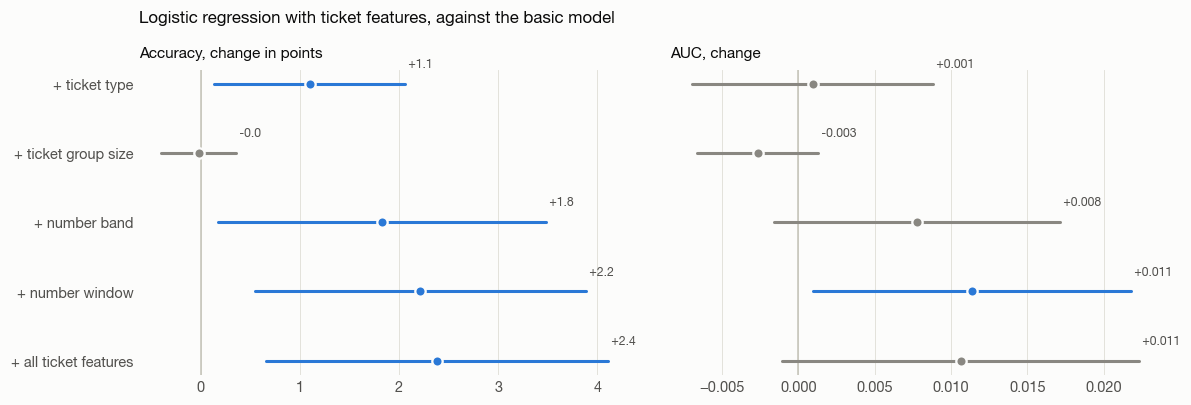

Blue: a gain that clears the interval. Orange: a loss that clears it. Grey: no detectable change.

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True, gridspec_kw={"wspace": 0.08})
names = list(cmp_acc.index)
yy = np.arange(len(names))
for ax, (cm, scale, ttl, unit) in zip(axes, [(cmp_acc, 100, "Accuracy, change in points", "{:+.1f}"),
                                               (cmp_auc, 1, "AUC, change", "{:+.3f}")]):
    for i, nm in enumerate(names):
        r = cm.loc[nm]
        col = BLUE if r["lo"] > 0 else ORANGE if r["hi"] < 0 else MUTED
        ax.plot([scale * r["lo"], scale * r["hi"]], [i, i], color=col, linewidth=2, solid_capstyle="round", zorder=3)
        ax.scatter([scale * r["diff"]], [i], s=46, color=col, edgecolor=SURFACE, linewidth=1.5, zorder=4)
        ax.text(scale * r["hi"], i - 0.28, " " + unit.format(scale * r["diff"]), fontsize=8, color=INK2, va="center")
    ax.axvline(0, color=AXIS, linewidth=1, zorder=2)
    ax.grid(axis="x", color=GRID, linewidth=0.6); ax.tick_params(length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_title(ttl, loc="left", fontsize=10, pad=8)
axes[0].set_yticks(yy, names); axes[0].invert_yaxis()
fig.suptitle("Logistic regression with ticket features, against the basic model", x=0.125, ha="left", fontsize=11, y=1.03)
plt.show()
display(Markdown("Blue: a gain that clears the interval. Orange: a loss that clears it. Grey: no detectable change."))

Every ticket set except group size clears 0 on accuracy, but the intervals are wide: the window's +2.2 points could be anywhere from about +0.5 to +3.9. On AUC only the window clears 0. A gain of 1 to 3 points is worth keeping in a model but not worth expecting to hold exactly on the test set.

## Which ticket columns the full model leans on

Logistic regression fitted once on all of train with every ticket feature. Numeric inputs are standardised and categories are 0/1 columns. A positive coefficient raises the odds of survival, holding the other features fixed. Regularisation pulls coefficients for small groups towards 0, but some groups below hold only a handful of train passengers. The 12 ticket columns with the largest coefficients either way are shown.

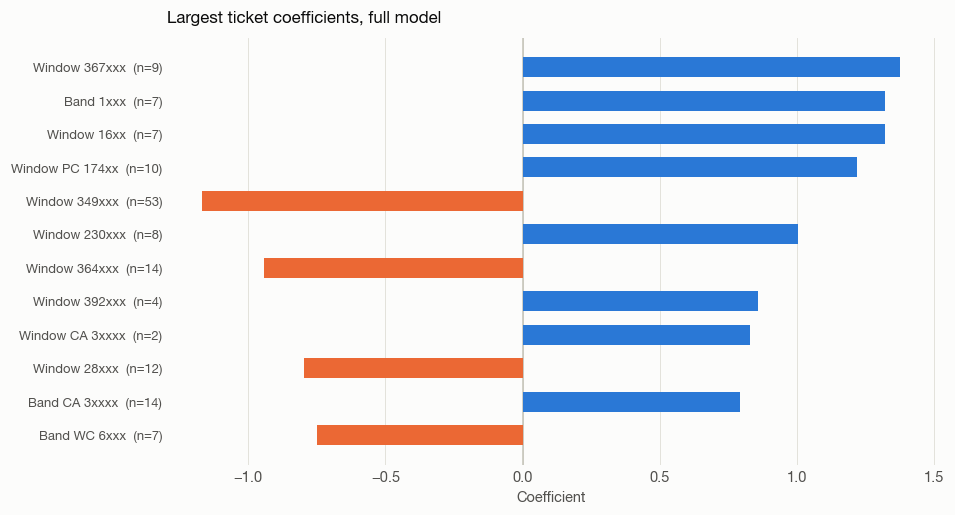

Basic-feature coefficients in the same model, for scale: Sex_female +1.40, Sex_male -1.37, Pclass_1 +0.70, Pclass_3 -0.55, Age -0.55, LogFare +0.51, SibSp -0.33, Embarked_S -0.21, AgeMissing -0.14, Embarked_Q +0.14, Pclass_2 -0.12, Embarked_C +0.10, Parch -0.01.

In [4]:
cat, num = SETS["+ all ticket features"]
m = pipe(cat, num, LogisticRegression(max_iter=5000)).fit(tr, y)
names_ = m[0].get_feature_names_out()
co = pd.Series(m[-1].coef_[0], index=[n.split("__", 1)[1] for n in names_])
tick = co[[any(n.startswith(p) for p in ["TicketTypeG_", "BandG_", "WindowG_", "TicketCount"]) for n in co.index]]
top = tick.reindex(tick.abs().sort_values(ascending=False).index[:12])
n_tr = {}
for n in top.index:
    col, val = (n.split("_", 1) + [None])[:2]
    n_tr[n] = int((tr[col] == val).sum()) if val is not None and col in tr else len(tr)
lab = [n.replace("TicketTypeG_", "Type ").replace("BandG_", "Band ").replace("WindowG_", "Window ")
       .replace("TicketCount", "Ticket group size") + (f"  (n={n_tr[n]})" if n != "TicketCount" else "") for n in top.index]
fig, ax = plt.subplots(figsize=(9, 0.32 * len(top) + 1.2))
ax.barh(range(len(top)), top.values, height=0.6, color=[BLUE if v > 0 else ORANGE for v in top.values], zorder=3)
ax.set_yticks(range(len(top)), lab, fontsize=8.5); ax.invert_yaxis()
ax.axvline(0, color=AXIS, linewidth=1)
ax.grid(axis="x", color=GRID, linewidth=0.6); ax.tick_params(length=0)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_xlabel("Coefficient")
ax.set_title("Largest ticket coefficients, full model", loc="left", fontsize=11, pad=10)
plt.show()
basic = co[[n.split("_")[0] in BASIC_CAT or n in BASIC_NUM for n in co.index]]
b = basic.reindex(basic.abs().sort_values(ascending=False).index)
display(Markdown("Basic-feature coefficients in the same model, for scale: " +
                 ", ".join(f"{k} {v:+.2f}" for k, v in b.items()) + "."))

The strongest ticket columns are small windows: 367xxx (9 train passengers, 67% survived), 16xx (7), PC 174xx (10, 90% survived), 230xxx (8, 88% survived). The one large window with a strong weight is 349xxx (53 train passengers, 6% survived against 19% expected from class and sex). Sex and class still carry the largest weights. Because the strong windows are small and family-shaped, the ticket gain is likely the same signal as family survival.

## Does the ticket encode the deck?

Two tests on the 295 passengers with a cabin recorded, scoring each passenger leave-one-out (their own cabin hidden):

- **Same ticket.** Guess the deck from other passengers on the exact same ticket.
- **Neighbouring ticket numbers.** Guess the deck from the nearest other ticket number with the same prefix and class, on a different ticket.

In [5]:
k = c[c["Cabin"].notna()].copy()
k["D"] = k["Cabin"].str[0]
base_rate = k["D"].value_counts(normalize=True).iloc[0]
hit = n = 0
for t, s in k.groupby("Ticket"):
    if len(s) < 2:
        continue
    for i in s.index:
        n += 1; hit += s.drop(i)["D"].value_counts().index[0] == s.loc[i, "D"]
rows = [("Same ticket", n, hit / n)]
k["pre"] = k["TicketType"]
nb_ = []
for i, r in k[k["TicketNum"].notna()].iterrows():
    o = k[(k["Ticket"] != r["Ticket"]) & (k["pre"] == r["pre"]) & (k["Pclass"] == r["Pclass"]) & k["TicketNum"].notna()]
    if o.empty:
        continue
    dist = (o["TicketNum"] - r["TicketNum"]).abs(); j = dist.idxmin()
    nb_.append((dist[j], o.loc[j, "D"] == r["D"]))
nb_ = pd.DataFrame(nb_, columns=["dist", "hit"])
for lo, hi, lab in [(1, 2, "Neighbouring ticket, 1 to 2 numbers away"), (3, 10, "Neighbouring ticket, 3 to 10 away"),
                    (11, 100, "Neighbouring ticket, 11 to 100 away")]:
    s = nb_[(nb_["dist"] >= lo) & (nb_["dist"] <= hi)]
    rows.append((lab, len(s), s["hit"].mean()))
rows.append(("No ticket information (most common deck, C)", len(k), base_rate))
t = pd.DataFrame(rows, columns=["Guess from", "Passengers scored", "Deck right"])
t["Deck right"] = (100 * t["Deck right"]).round(0).astype(int).astype(str) + "%"
display(t.style.hide(axis="index"))
filled = int((c["Deck"].notna() & c["Cabin"].isna()).sum()) if "Deck" in c else 0
display(Markdown(
    f"Passengers on the same ticket share a deck almost every time, because they are one party in adjacent cabins. "
    f"The ticket number itself carries no deck information: a ticket 1 or 2 numbers away is barely better than guessing deck C for everyone (36% against 32%). "
    f"The `Deck` column in the data files therefore takes the passenger's own cabin, else the deck of a ticket-mate with a cabin recorded, "
    f"and is blank otherwise. That fills {filled} passengers beyond the {int(c['Cabin'].notna().sum())} with a cabin recorded; "
    f"{int(c['Deck'].isna().sum())} of {len(c):,} stay blank, almost all of them 2nd and 3rd class."
))

Guess from,Passengers scored,Deck right
Same ticket,198,98%
"Neighbouring ticket, 1 to 2 numbers away",142,36%
"Neighbouring ticket, 3 to 10 away",62,35%
"Neighbouring ticket, 11 to 100 away",43,42%
"No ticket information (most common deck, C)",295,32%


Passengers on the same ticket share a deck almost every time, because they are one party in adjacent cabins. The ticket number itself carries no deck information: a ticket 1 or 2 numbers away is barely better than guessing deck C for everyone (36% against 32%). The `Deck` column in the data files therefore takes the passenger's own cabin, else the deck of a ticket-mate with a cabin recorded, and is blank otherwise. That fills 16 passengers beyond the 295 with a cabin recorded; 998 of 1,309 stay blank, almost all of them 2nd and 3rd class.